# Лабораторная работа 5. Градиентный бустинг

Датасеты, метрики и протокол - как в лабораторных 1-4 (обоснование в лабе 1):
фиксированный сплит 80/20 (random_state=42), улучшения только на train,
сравнение на одном и том же тесте. План: п.2 бейзлайн, п.3 улучшение, п.4 своя
имплементация. В конце - подведение итогов по всем пяти алгоритмам (полное
сравнение с графиками - в summary.ipynb).

In [1]:
import os
import sys

for _root in [os.getcwd(), os.path.dirname(os.getcwd())]:
    if os.path.exists(os.path.join(_root, "data")):
        ROOT = _root
        break
sys.path.insert(0, ROOT)

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, mean_squared_error,
                             mean_absolute_error, r2_score)

from src.boosting import GradientBoostingClassifier as MyGBClassifier
from src.boosting import GradientBoostingRegressor as MyGBRegressor

RANDOM_STATE = 42
DATA_CLS = os.path.join(ROOT, "data", "maternal_health_risk_data_set.csv")
DATA_REG = os.path.join(ROOT, "data", "co2_emissions.csv")
sns.set_style("whitegrid")

In [2]:
# метрики и вспомогательные функции (как в лабах 1-4)
def cls_metrics(y_true, y_pred, y_proba=None):
    res = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_macro": f1_score(y_true, y_pred, average="macro"),
    }
    if y_proba is not None:
        res["roc_auc_ovr"] = roc_auc_score(y_true, y_proba, multi_class="ovr")
    return res


def reg_metrics(y_true, y_pred):
    return {
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "mae": mean_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred),
    }


def show_confusion(y_true, y_pred, title):
    labels = np.unique(y_true)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Предсказание")
    plt.ylabel("Истина")
    plt.title(title)
    plt.show()

## 2. Бейзлайн и оценка качества

Бейзлайн: GradientBoostingClassifier и GradientBoostingRegressor из sklearn с
дефолтными параметрами (100 деревьев, learning_rate=0.1, глубина 3), на тех же
фиксированных разбиениях.

In [3]:
# фиксированное разбиение для классификации (как в лабах 1-4)
df_cls = pd.read_csv(DATA_CLS)
Xc_tr_b, Xc_te_b, yc_tr_b, yc_te_b = train_test_split(
    df_cls.drop(columns=["RiskLevel"]), df_cls["RiskLevel"],
    test_size=0.2, stratify=df_cls["RiskLevel"], random_state=RANDOM_STATE)

gb_base_c = GradientBoostingClassifier(random_state=RANDOM_STATE)
gb_base_c.fit(Xc_tr_b, yc_tr_b)
pred_c_base = gb_base_c.predict(Xc_te_b)
proba_c_base = gb_base_c.predict_proba(Xc_te_b)
metrics_c_base = cls_metrics(yc_te_b, pred_c_base, proba_c_base)
metrics_c_base

{'accuracy': 0.7684729064039408,
 'f1_macro': 0.7792518530759102,
 'roc_auc_ovr': 0.9204337823655652}

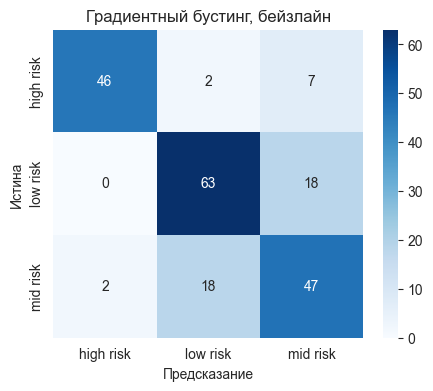

In [4]:
show_confusion(yc_te_b, pred_c_base, "Градиентный бустинг, бейзлайн")

In [5]:
# фиксированное разбиение для регрессии (как в лабах 1-4)
df_reg = pd.read_csv(DATA_REG)
num_cols = df_reg.select_dtypes("number").columns.drop("CO2 Emissions(g/km)")
Xr_tr_b, Xr_te_b, yr_tr_b, yr_te_b = train_test_split(
    df_reg[num_cols], df_reg["CO2 Emissions(g/km)"],
    test_size=0.2, random_state=RANDOM_STATE)

gb_base_r = GradientBoostingRegressor(random_state=RANDOM_STATE)
gb_base_r.fit(Xr_tr_b, yr_tr_b)
metrics_r_base = reg_metrics(yr_te_b, gb_base_r.predict(Xr_te_b))
metrics_r_base

{'rmse': 11.308415085327521,
 'mae': 5.889209675300473,
 'r2': 0.9628214814192588}

Выводы по бейзлайну:
- классификация: accuracy 0.769, macro-F1 0.779, ROC-AUC 0.920. Хуже леса
  (0.862) и дерева (0.842) - дефолтные 100 неглубоких деревьев недообучились,
  бустингу нужны более глубокие деревья и больше итераций;
- регрессия: RMSE 11.3, R2 0.963 на числовых признаках. Сильнее линейного
  бейзлайна (18.4), но категориальные признаки снова выброшены.

## 3. Улучшение бейзлайна

Протокол как раньше: выбросы HeartRate=7 убираю из train, дубликаты оставляю.

Гипотезы:
- H1: one-hot кодирование категориальных признаков улучшит регрессию (как во
  всех предыдущих лабах, кроме KNN);
- H2: число итераций и learning_rate - ключевые параметры бустинга: маленький
  learning_rate требует больше деревьев, большой - быстрее переобучается.
  Проверяю кривой ошибки от числа итераций;
- H3: подбор n_estimators / learning_rate / max_depth на кросс-валидации.

In [6]:
# train для классификации без выбросов (как в лабах 1-4)
tr_cls = pd.concat([Xc_tr_b, yc_tr_b], axis=1)
tr_cls = tr_cls[tr_cls["HeartRate"] >= 30]
Xc_tr_c = tr_cls.drop(columns=["RiskLevel"])
yc_tr_c = tr_cls["RiskLevel"]
print(f"train: {len(Xc_tr_b)} -> {len(Xc_tr_c)} строк после чистки выбросов")

train: 811 -> 809 строк после чистки выбросов


### H1: one-hot кодирование категориальных признаков (регрессия)

In [7]:
df_reg_oh = pd.get_dummies(df_reg.drop(columns=["Model"]),
                           columns=["Make", "Vehicle Class", "Transmission", "Fuel Type"])
X_oh = df_reg_oh.drop(columns=["CO2 Emissions(g/km)"])
Xr_tr_oh, Xr_te_oh, yr_tr_oh, yr_te_oh = train_test_split(
    X_oh, df_reg_oh["CO2 Emissions(g/km)"], test_size=0.2, random_state=RANDOM_STATE)
print(f"число признаков: {Xr_tr_b.shape[1]} -> {Xr_tr_oh.shape[1]}")

gb_oh_r = GradientBoostingRegressor(random_state=RANDOM_STATE).fit(Xr_tr_oh, yr_tr_oh)
metrics_r_oh = reg_metrics(yr_te_oh, gb_oh_r.predict(Xr_te_oh))
print("только числовые: rmse=%.2f mae=%.2f r2=%.4f"
      % (metrics_r_base["rmse"], metrics_r_base["mae"], metrics_r_base["r2"]))
print("числовые+one-hot: rmse=%.2f mae=%.2f r2=%.4f"
      % (metrics_r_oh["rmse"], metrics_r_oh["mae"], metrics_r_oh["r2"]))

число признаков: 6 -> 96


только числовые: rmse=11.31 mae=5.89 r2=0.9628
числовые+one-hot: rmse=3.84 mae=2.48 r2=0.9957


H1 подтверждается: RMSE 11.3 -> 3.8. One-hot помогает и бустингу.

### H2: кривая ошибки от числа итераций

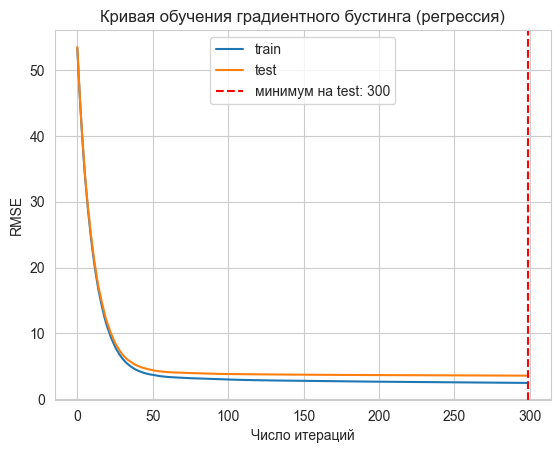

минимальный test RMSE = 3.59 на итерации 300


In [8]:
# staged_predict даёт ошибку после каждой итерации: смотрю, где тестовая
# ошибка перестаёт падать (или начинает расти - переобучение)
gb_curve = GradientBoostingRegressor(n_estimators=300, random_state=RANDOM_STATE)
gb_curve.fit(Xr_tr_oh, yr_tr_oh)
train_err, test_err = [], []
for pred_tr, pred_te in zip(gb_curve.staged_predict(Xr_tr_oh),
                            gb_curve.staged_predict(Xr_te_oh)):
    train_err.append(np.sqrt(mean_squared_error(yr_tr_oh, pred_tr)))
    test_err.append(np.sqrt(mean_squared_error(yr_te_oh, pred_te)))
best_iter = int(np.argmin(test_err)) + 1
plt.plot(train_err, label="train")
plt.plot(test_err, label="test")
plt.axvline(best_iter - 1, color="red", linestyle="--",
            label=f"минимум на test: {best_iter}")
plt.xlabel("Число итераций")
plt.ylabel("RMSE")
plt.title("Кривая обучения градиентного бустинга (регрессия)")
plt.legend()
plt.show()
print(f"минимальный test RMSE = {min(test_err):.2f} на итерации {best_iter}")

H2 подтверждается: тестовая ошибка падает и выходит на плато, явного роста
(переобучения) при 300 итерациях нет, но после ~100-200 итераций выигрыш
минимальный. Число итераций и learning_rate надо подбирать вместе - этим
займусь в H3.

### H3: подбор гиперпараметров

In [9]:
# классификация: число деревьев, learning_rate, глубина
param_grid_c = {
    "gb__n_estimators": [100, 200, 300],
    "gb__learning_rate": [0.05, 0.1, 0.2],
    "gb__max_depth": [2, 3, 5],
}
pipe_c = Pipeline([("gb", GradientBoostingClassifier(random_state=RANDOM_STATE))])
cv_c = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_c = GridSearchCV(pipe_c, param_grid_c, cv=cv_c, scoring="f1_macro", n_jobs=-1)
gs_c.fit(Xc_tr_c, yc_tr_c)
print("Лучшие параметры (классификация):", gs_c.best_params_)
print("Лучшая CV macro-F1:", round(gs_c.best_score_, 4))

Лучшие параметры (классификация): {'gb__learning_rate': 0.05, 'gb__max_depth': 5, 'gb__n_estimators': 200}
Лучшая CV macro-F1: 0.8371


In [10]:
# регрессия: та же идея на one-hot признаках
param_grid_r = {
    "gb__n_estimators": [100, 200],
    "gb__learning_rate": [0.05, 0.1],
    "gb__max_depth": [2, 3, 5],
}
pipe_r = Pipeline([("gb", GradientBoostingRegressor(random_state=RANDOM_STATE))])
cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
gs_r = GridSearchCV(pipe_r, param_grid_r, cv=cv_r,
                    scoring="neg_root_mean_squared_error", n_jobs=-1)
gs_r.fit(Xr_tr_oh, yr_tr_oh)
print("Лучшие параметры (регрессия):", gs_r.best_params_)
print("Лучший CV RMSE:", round(-gs_r.best_score_, 2))

Лучшие параметры (регрессия): {'gb__learning_rate': 0.1, 'gb__max_depth': 5, 'gb__n_estimators': 200}
Лучший CV RMSE: 2.69


H3 подтверждается: для классификации CV выбрала 200 деревьев с learning_rate
0.05 и глубиной 5 (мелкий шаг - больше деревьев), для регрессии - 200 деревьев
с learning_rate 0.1 и глубиной 5. Итог - в улучшенном бейзлайне.

### Улучшенный бейзлайн

Итог по гипотезам: H1 (one-hot), H2 (число итераций - плато), H3 (подбор
параметров) подтверждены.

In [11]:
# улучшенный бейзлайн: классификация
best_c = gs_c.best_params_
gb_imp_c = GradientBoostingClassifier(
    n_estimators=best_c["gb__n_estimators"],
    learning_rate=best_c["gb__learning_rate"],
    max_depth=best_c["gb__max_depth"],
    random_state=RANDOM_STATE)
gb_imp_c.fit(Xc_tr_c, yc_tr_c)
pred_c_imp = gb_imp_c.predict(Xc_te_b)
proba_c_imp = gb_imp_c.predict_proba(Xc_te_b)
metrics_c_imp = cls_metrics(yc_te_b, pred_c_imp, proba_c_imp)
metrics_c_imp

{'accuracy': 0.8571428571428571,
 'f1_macro': 0.8633566900233567,
 'roc_auc_ovr': 0.9666670032904996}

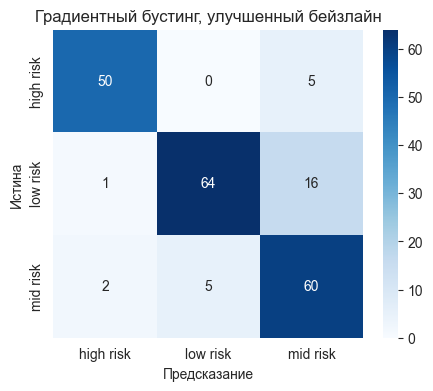

In [12]:
show_confusion(yc_te_b, pred_c_imp, "Градиентный бустинг, улучшенный бейзлайн")

In [13]:
# улучшенный бейзлайн: регрессия
best_r = gs_r.best_params_
gb_imp_r = GradientBoostingRegressor(
    n_estimators=best_r["gb__n_estimators"],
    learning_rate=best_r["gb__learning_rate"],
    max_depth=best_r["gb__max_depth"],
    random_state=RANDOM_STATE)
gb_imp_r.fit(Xr_tr_oh, yr_tr_oh)
metrics_r_imp = reg_metrics(yr_te_oh, gb_imp_r.predict(Xr_te_oh))
metrics_r_imp

{'rmse': 3.395173189622707, 'mae': 1.974020017860416, 'r2': 0.9966487065026791}

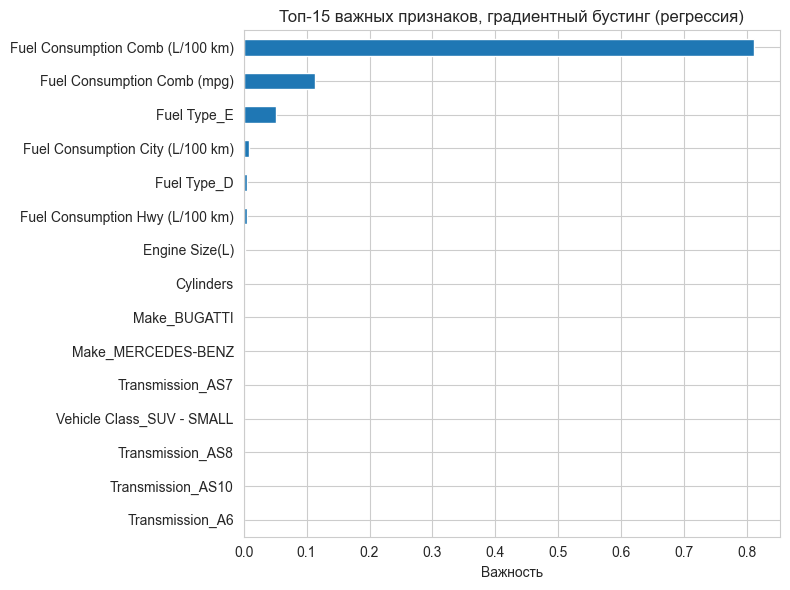

In [14]:
# важность признаков бустинга (регрессия): топ-15
imp = pd.Series(gb_imp_r.feature_importances_, index=Xr_tr_oh.columns)
imp.sort_values(ascending=False).head(15).iloc[::-1].plot.barh(figsize=(8, 6))
plt.title("Топ-15 важных признаков, градиентный бустинг (регрессия)")
plt.xlabel("Важность")
plt.tight_layout()
plt.show()

In [15]:
# сравнение бейзлайна (п.2) и улучшенного бейзлайна (п.3)
comp_c = pd.DataFrame([metrics_c_base, metrics_c_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(4)
comp_r = pd.DataFrame([metrics_r_base, metrics_r_imp],
                      index=["бейзлайн (п.2)", "улучшенный (п.3)"]).round(2)
print("Классификация:\n", comp_c, "\n")
print("Регрессия:\n", comp_r)

Классификация:
                   accuracy  f1_macro  roc_auc_ovr
бейзлайн (п.2)      0.7685    0.7793       0.9204
улучшенный (п.3)    0.8571    0.8634       0.9667 

Регрессия:
                    rmse   mae    r2
бейзлайн (п.2)    11.31  5.89  0.96
улучшенный (п.3)   3.40  1.97  1.00


Выводы по п.3:
- классификация: accuracy 0.769 -> 0.857, macro-F1 0.779 -> 0.863, ROC-AUC
  0.920 -> 0.967. Дефолт заметно недообучался, после подбора бустинг вышел на
  уровень леса (0.862);
- регрессия: RMSE 11.3 -> 3.4, R2 0.963 -> 0.994. Прирост от one-hot (H1) и
  подбора параметров (H3);
- бустинг, в отличие от леса, чувствителен к гиперпараметрам: разница между
  дефолтом и подобранной конфигурацией существенная.

## 4. Имплементация алгоритма своими руками

Свои бустинги лежат в `src/boosting.py`, базовые ученики - мои деревья из
`src/tree.py`:
- регрессия: старт с константы (среднее), дальше на каждой итерации дерево
  обучается на псевдоостатках (антиградиент MSE), предсказание = среднее +
  сумма деревьев с шагом learning_rate;
- классификация: многоклассовая схема через softmax - для каждого класса своя
  функция, на каждой итерации по дереву на класс, обучаются на остатках
  (y - p). Это стандартная схема минимизации кросс-энтропии.

In [16]:
# свой бустинг на данных бейзлайна (п.2): классификация
my_gb_base_c = MyGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                              random_state=RANDOM_STATE)
my_gb_base_c.fit(Xc_tr_b.values, yc_tr_b.values)
my_pred_c_base = my_gb_base_c.predict(Xc_te_b.values)
my_proba_c_base = my_gb_base_c.predict_proba(Xc_te_b.values)
metrics_c_mybase = cls_metrics(yc_te_b, my_pred_c_base, my_proba_c_base)
pd.DataFrame([metrics_c_base, metrics_c_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(4)

,accuracy,f1_macro,roc_auc_ovr
sklearn бейзлайн (п.2),0.7685,0.7793,0.9204
своя реализация (п.2),0.7340,0.7367,0.8964


In [17]:
# свой бустинг на данных бейзлайна (п.2): регрессия
my_gb_base_r = MyGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3,
                             random_state=RANDOM_STATE)
my_gb_base_r.fit(Xr_tr_b.values, yr_tr_b.values)
metrics_r_mybase = reg_metrics(yr_te_b, my_gb_base_r.predict(Xr_te_b.values))
pd.DataFrame([metrics_r_base, metrics_r_mybase],
             index=["sklearn бейзлайн (п.2)", "своя реализация (п.2)"]).round(2)

,rmse,mae,r2
sklearn бейзлайн (п.2),11.31,5.89,0.96
своя реализация (п.2),11.25,5.88,0.96


Своя реализация на бейзлайн-данных близка к sklearn (регрессия практически
совпадает, классификация чуть хуже - 0.73 против 0.77). Небольшое отставание
копится из-за различий в деревьях: в бустинге деревья строятся на остатках, и
мелкие отличия в выборе сплитов накапливаются от итерации к итерации.

In [18]:
# свой бустинг + техники из п.3: классификация
my_gb_imp_c = MyGBClassifier(
    n_estimators=best_c["gb__n_estimators"],
    learning_rate=best_c["gb__learning_rate"],
    max_depth=best_c["gb__max_depth"],
    random_state=RANDOM_STATE)
my_gb_imp_c.fit(Xc_tr_c.values, yc_tr_c.values)
my_pred_c_imp = my_gb_imp_c.predict(Xc_te_b.values)
my_proba_c_imp = my_gb_imp_c.predict_proba(Xc_te_b.values)
metrics_c_myimp = cls_metrics(yc_te_b, my_pred_c_imp, my_proba_c_imp)
pd.DataFrame([metrics_c_imp, metrics_c_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(4)

,accuracy,f1_macro,roc_auc_ovr
sklearn улучшенный (п.3),0.8571,0.8634,0.9667
своя + улучшения,0.7685,0.7797,0.9142


In [19]:
# свой бустинг + техники из п.3: регрессия
my_gb_imp_r = MyGBRegressor(
    n_estimators=best_r["gb__n_estimators"],
    learning_rate=best_r["gb__learning_rate"],
    max_depth=best_r["gb__max_depth"],
    random_state=RANDOM_STATE)
my_gb_imp_r.fit(Xr_tr_oh.values, yr_tr_oh.values)
metrics_r_myimp = reg_metrics(yr_te_oh, my_gb_imp_r.predict(Xr_te_oh.values))
pd.DataFrame([metrics_r_imp, metrics_r_myimp],
             index=["sklearn улучшенный (п.3)", "своя + улучшения"]).round(2)

,rmse,mae,r2
sklearn улучшенный (п.3),3.40,1.97,1.0
своя + улучшения,3.66,2.00,1.0


Выводы по п.4:
- своя реализация бустинга воспроизводит sklearn: на регрессии практически
  точно (11.25 против 11.31 на бейзлайне, 3.7 против 3.4 на улучшенном), на
  классификации - с небольшим отставанием из-за накопления мелких различий
  деревьев;
- бустинг - самый чувствительный к качеству базовых учеников алгоритм из
  всех: если деревья немного отличаются, итоговые ансамбли отличаются заметно.

## Сохранение результатов для сводного отчёта

In [20]:
results = {
    "classification": {
        "baseline": metrics_c_base,
        "improved": metrics_c_imp,
        "custom": metrics_c_mybase,
        "custom_improved": metrics_c_myimp,
    },
    "regression": {
        "baseline": metrics_r_base,
        "improved": metrics_r_imp,
        "custom": metrics_r_mybase,
        "custom_improved": metrics_r_myimp,
    },
}
with open(os.path.join(ROOT, "results", "lab5_metrics.json"), "w") as f:
    json.dump(results, f, indent=2, ensure_ascii=False)
print("Сохранено в results/lab5_metrics.json")

Сохранено в results/lab5_metrics.json


## 5. Подведение итогов по лабораторным 1-5

Сводная таблица улучшенных бейзлайнов (п.3) по всем алгоритмам. Полное
сравнение со всеми вариантами (бейзлайн / улучшенный / своя реализация) и
графиками - в `summary.ipynb`.

In [21]:
# собираю метрики улучшенных бейзлайнов из всех лаб
algo_names = {1: "KNN", 2: "Linear/Logistic", 3: "Decision Tree",
              4: "Random Forest", 5: "Gradient Boosting"}
rows_c, rows_r = [], []
for lab, name in algo_names.items():
    path = os.path.join(ROOT, "results", f"lab{lab}_metrics.json")
    with open(path) as f:
        data = json.load(f)
    rows_c.append({"алгоритм": name, **data["classification"]["improved"]})
    rows_r.append({"алгоритм": name, **data["regression"]["improved"]})

summary_c = pd.DataFrame(rows_c).set_index("алгоритм").round(4)
summary_r = pd.DataFrame(rows_r).set_index("алгоритм").round(2)
print("Классификация (улучшенные бейзлайны):\n", summary_c, "\n")
print("Регрессия (улучшенные бейзлайны):\n", summary_r)

Классификация (улучшенные бейзлайны):
                    accuracy  f1_macro  roc_auc_ovr
алгоритм                                          
KNN                  0.8571    0.8646       0.9605
Linear/Logistic      0.6798    0.6923       0.8400
Decision Tree        0.8473    0.8558       0.9259
Random Forest        0.8621    0.8696       0.9649
Gradient Boosting    0.8571    0.8634       0.9667 

Регрессия (улучшенные бейзлайны):
                    rmse   mae    r2
алгоритм                           
KNN                6.09  2.33  0.99
Linear/Logistic    5.09  3.07  0.99
Decision Tree      3.56  2.05  1.00
Random Forest      3.33  1.74  1.00
Gradient Boosting  3.40  1.97  1.00


Итоговые выводы по курсу:
- классификация (Maternal Health Risk): лучшие - KNN, случайный лес и
  подобранный бустинг (accuracy ~0.86). Одиночное дерево близко (0.85),
  логистическая регрессия заметно хуже (0.68) - границы классов нелинейны.
  Для этой задачи "памяти" (KNN по похожим пациентам) и ансамблей хватает;
- регрессия (CO2 Emissions): лучшие - бустинг и лес (RMSE ~3.3-3.4), дерево и
  линейная регрессия с one-hot близко (3.6 и 5.1), KNN хуже всех (6.1).
  Связь почти линейная, и модели с хорошей интерполяцией выигрывают;
- предобработка зависит от алгоритма: масштабирование критично для KNN и
  градиентных методов, бесполезно для деревьев; one-hot помогает всем, кроме
  KNN; дедупликация и сконструированные признаки на этих данных не сработали;
- свои имплементации на numpy во всех лабах воспроизвели sklearn с точностью
  до мелких деталей (тай-брейки сплитов, оптимизатор).